In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from google.colab import files

In [2]:
os.makedirs('images', exist_ok=True)

uploaded = files.upload()

for filename in uploaded.keys():
    dest = os.path.join('images', filename)
    os.rename(filename, dest)
    image_path = dest
    print(f"File '{filename}' Moved To '{dest}'.")

print("\nContents Of Images Folder:")
print(os.listdir('images'))

Saving Practice Picture.jpg to Practice Picture.jpg
File 'Practice Picture.jpg' Moved To 'images/Practice Picture.jpg'.

Contents Of Images Folder:
['Practice Picture.jpg']


In [3]:
image = cv2.imread(image_path)
height, width = image.shape[:2]

angle = 30
center = (width // 2, height // 2)
scale = 1.0

rotation_matrix = cv2.getRotationMatrix2D(center, angle, scale)

tx = 10
ty = 0
translation_matrix = np.float32([[1, 0, tx], [0, 1, ty]])

R = np.vstack((rotation_matrix, np.array([0, 0, 1])))
T = np.vstack((translation_matrix, np.array([0, 0, 1])))

final_matrix = T @ R
final_matrix = final_matrix[:2, :]

print("Final Combined Affine Matrix (2x3):")
print(final_matrix)

Final Combined Affine Matrix (2x3):
[[ 8.66025404e-01  5.00000000e-01 -9.07991713e+02]
 [-5.00000000e-01  8.66025404e-01  1.59000829e+03]]


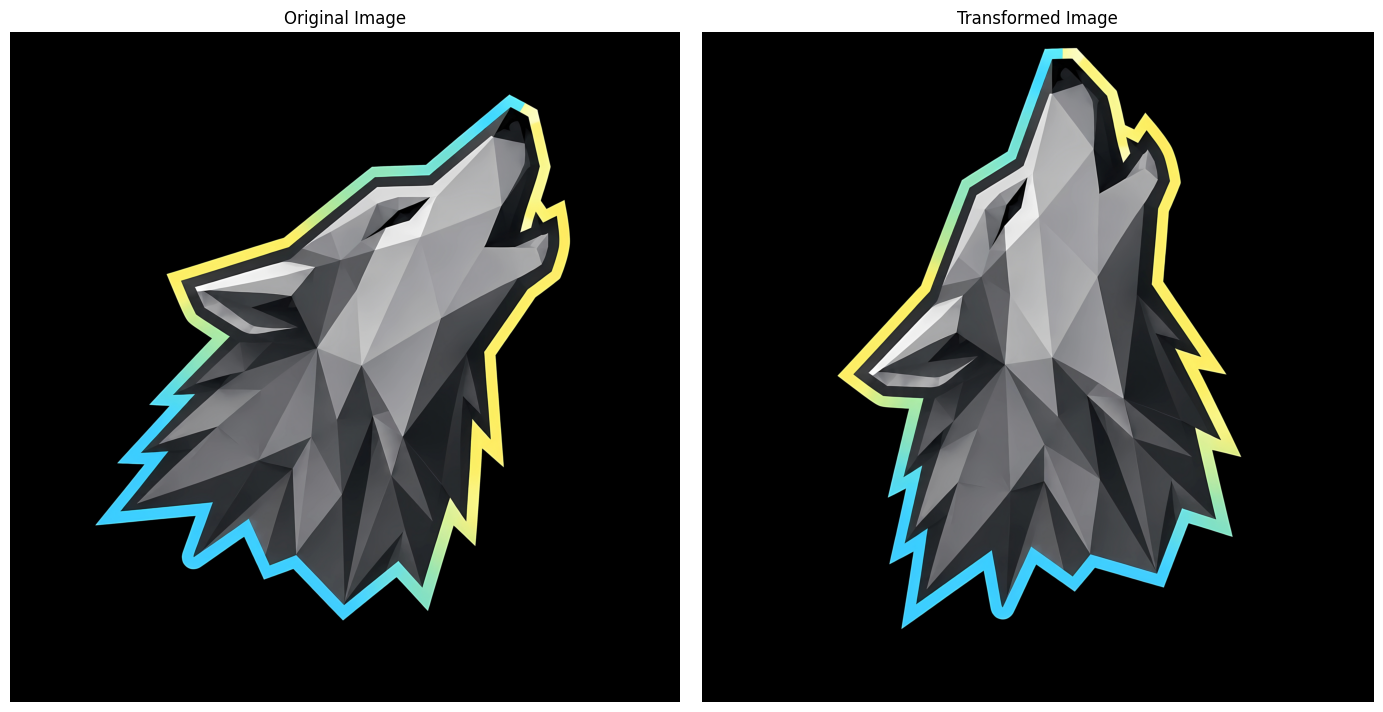

In [4]:
result = cv2.warpAffine(image, final_matrix, (width + tx, height))

plt.figure(figsize=(14, 7))

plt.subplot(1, 2, 1)
plt.imshow(image[..., ::-1])
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(result[..., ::-1])
plt.title('Transformed Image')
plt.axis('off')

plt.tight_layout()
plt.show()